# Seaborn

In [2]:
# Def:- Seaborn is a high level visualizations library
# seaborn is designed over the matplotib
# seaborn is used for complex chart, mainly used for statistical charts, KDE plot, pariplot
# Seaborn libarary have inbuild datasets


In [3]:
pip install seaborn


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Install & import seaborn

In [4]:
# pip install seaborn
import seaborn as sns


# Build in dataset

In [5]:
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


In [6]:
# How to Load the datasets from seaborn

df=sns.load_dataset('titanic')
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [7]:
df1=sns.load_dataset('flights')
df1

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


# Line Chart in Seaborn

In [8]:
import matplotlib.pyplot as plt

In [9]:
# Use: trends over the time
timeline=df1.groupby("year")["passengers"].sum().reset_index()
timeline

,year,passengers
0,1949,1520
1,1950,1676
2,1951,2042
3,1952,2364
4,1953,2700
5,1954,2867
6,1955,3408
7,1956,3939
8,1957,4421
9,1958,4572


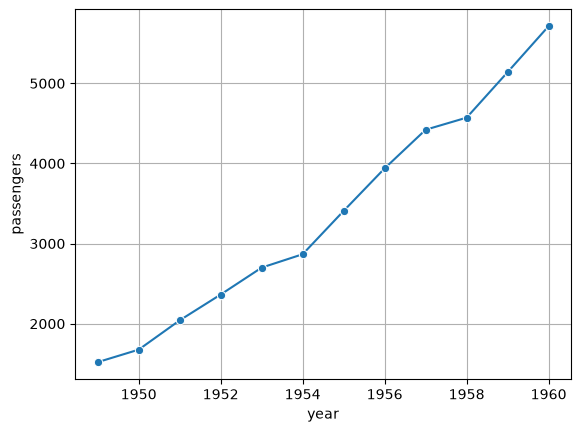

In [10]:
sns.lineplot(x="year",y="passengers",data=timeline, marker='o')
plt.grid()

# tips dataset


In [11]:
df=sns.load_dataset('tips')
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<Axes: xlabel='total_bill', ylabel='tip'>

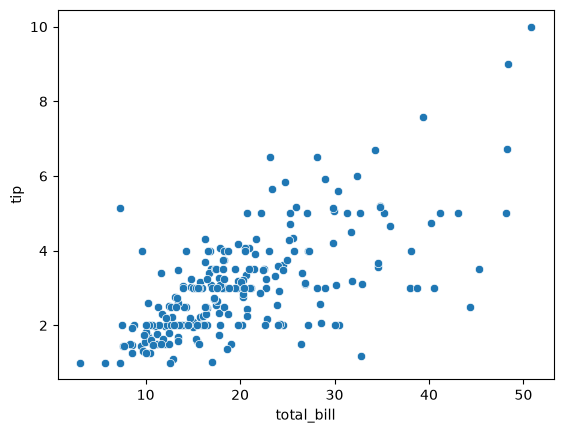

In [12]:
# Quey: find the relationship between total_bill and tip?
sns.scatterplot(x="total_bill",y="tip",data=df)

# Pairplot

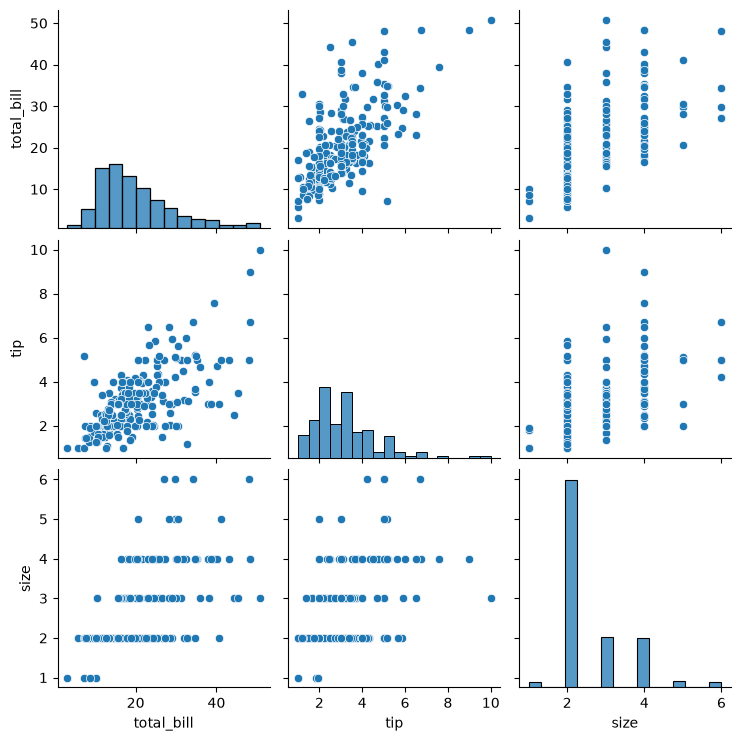

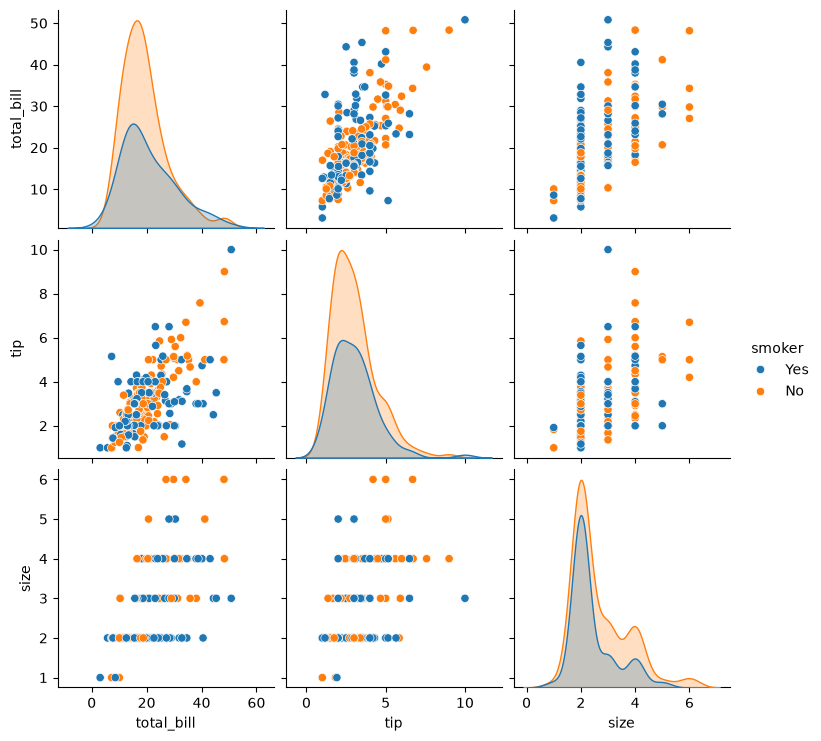

In [13]:
# USE:- Pair plot show the relationships between all the numerical variable together  pair- wise
# Hue:- help to make catogircal dataa
sns.pairplot(df)
sns.pairplot(df,hue='smoker')

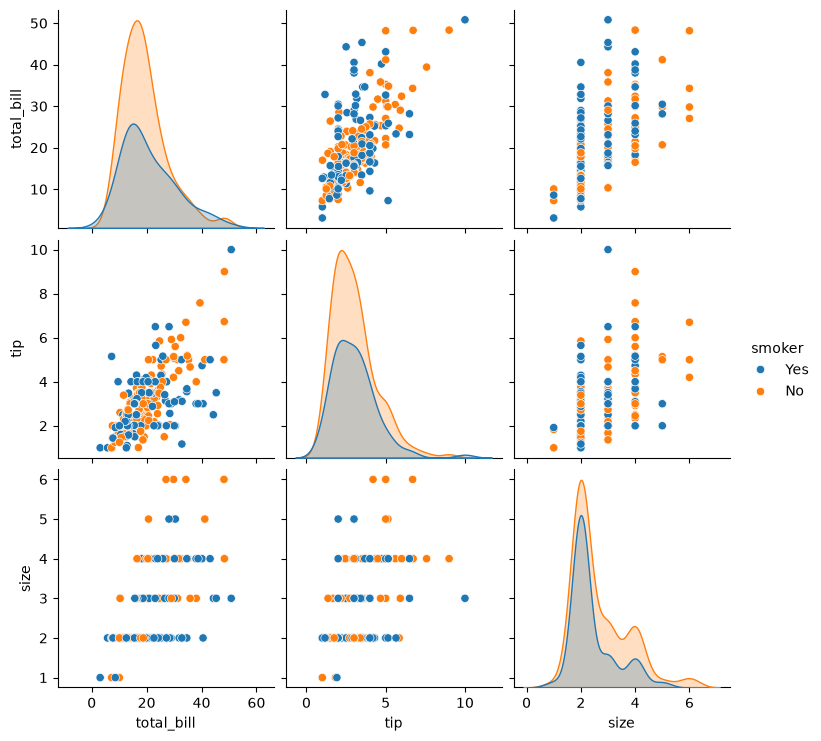

In [14]:
sns.pairplot(df,hue='smoker')

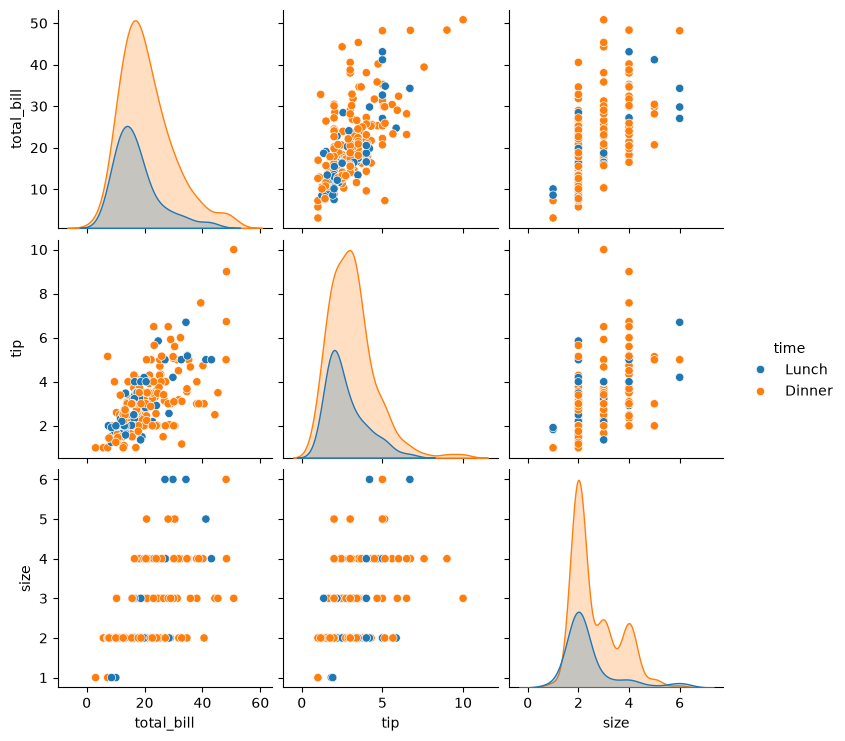

In [15]:
sns.pairplot(df,hue='time')

# Heatmap 

In [16]:
# USE:- is used to visulaize the correlation between 2 variables in colorful chart
# df.corr() :- this fuction work on numerical data
corr_matric=df.corr(numeric_only=True)
print(corr_matric)

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


<Axes: >

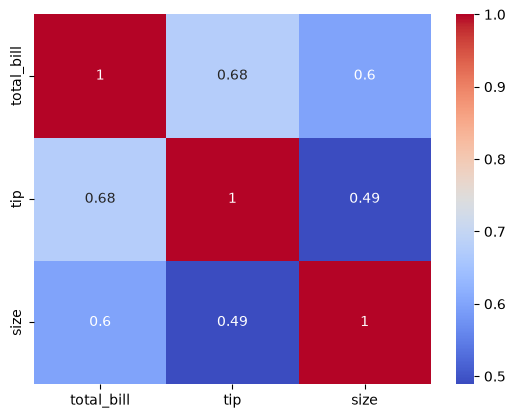

In [17]:
sns.heatmap(corr_matric,annot=True,cmap='coolwarm') # here annot a will hlep to print the values on the figure

# Relationship between Categorical COlumns

In [18]:
# using pivot  table:- to find the relationship between categorical variable
# Heatmap() make the colorful table for showing pivot table

In [19]:
# categorical columns:  sex, day, time, smoker

pivot=df.pivot_table(index='day',columns='sex', aggfunc='size')
pivot

sex,Male,Female
day,,
Thur,30,32
Fri,10,9
Sat,59,28
Sun,58,18


<Axes: xlabel='sex', ylabel='day'>

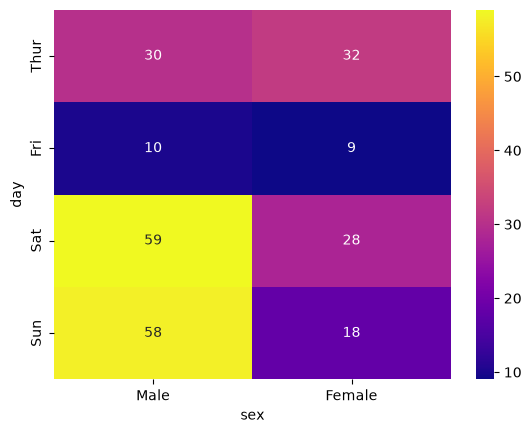

In [20]:
sns.heatmap(pivot,annot=True,cmap='plasma')

In [21]:
pivot=df.pivot_table(index=['day','time'],columns=['sex','smoker'],aggfunc='size',fill_value=0)
pivot

sex         Male     Female    
smoker       Yes  No    Yes  No
day  time                      
Thur Lunch    10  20      7  24
     Dinner    0   0      0   1
Fri  Lunch     3   0      3   1
     Dinner    5   2      4   1
Sat  Dinner   27  32     15  13
Sun  Dinner   15  43      4  14

<Axes: xlabel='sex-smoker', ylabel='day-time'>

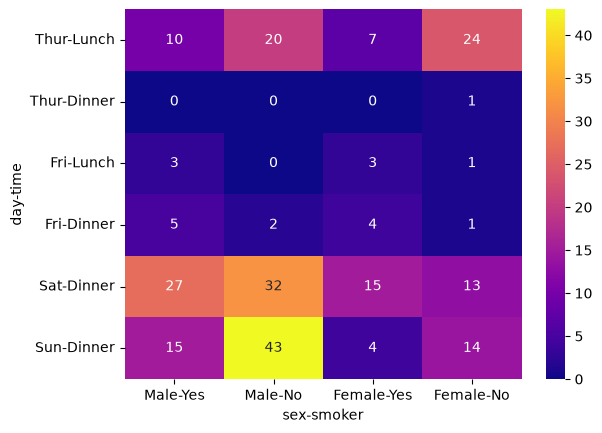

In [22]:
sns.heatmap(pivot,annot=True,cmap='plasma')

# Countplot:- Showing frequency of Categorical data

<Axes: xlabel='day', ylabel='count'>

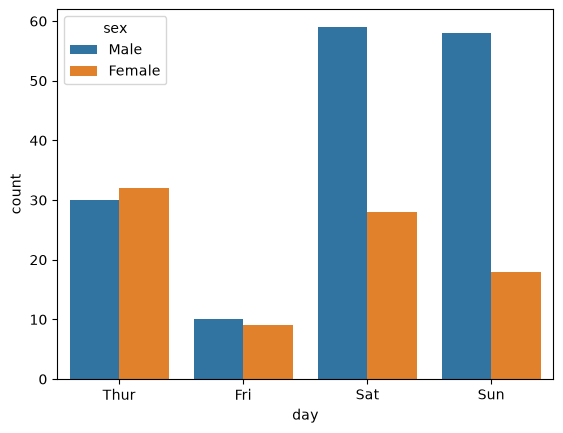

In [23]:
sns.countplot(data=df,x='day',hue='sex')

In [24]:
df=sns.load_dataset('tips')
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [28]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

<Axes: xlabel='day', ylabel='total_bill'>

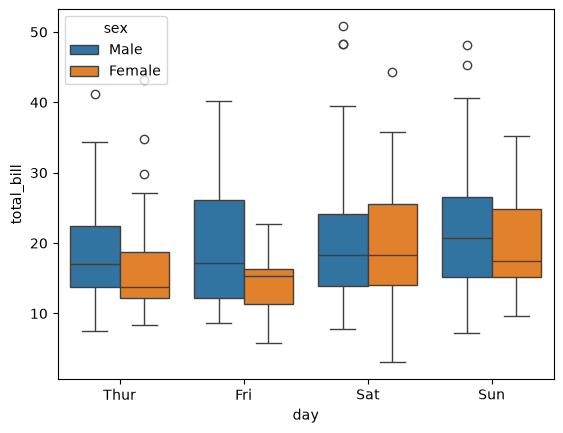

In [ ]:
# finding the daywise distribution of total_bill with respect to sex
sns.boxplot(data=df,x='day',y='total_bill',hue='sex')

<Axes: xlabel='day', ylabel='tip'>

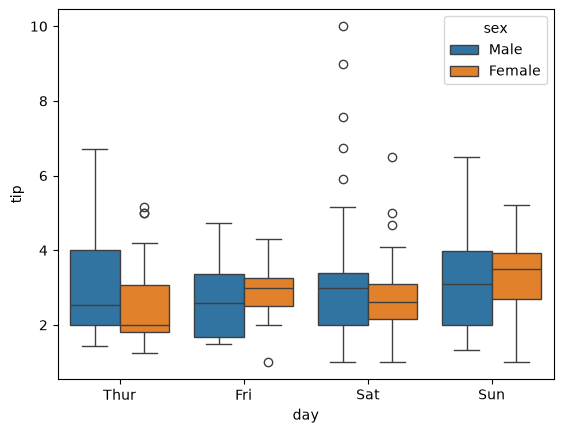

In [26]:
sns.boxplot(data=df,x='day',y='tip',hue='sex')

# Density plot (KDE Plot) Kernal Density Estimate

<Axes: xlabel='total_bill', ylabel='Density'>

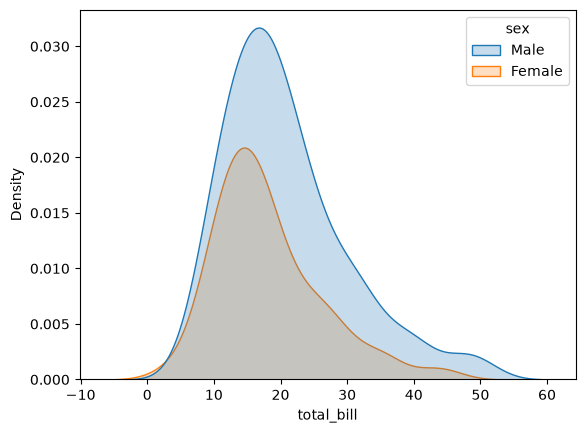

In [32]:
# KDE plot:- is used to find the distribution of the data. It is used to find the probability density function

sns.kdeplot(data=df,x='total_bill',hue='sex',fill=True)

<Axes: xlabel='total_bill', ylabel='Density'>

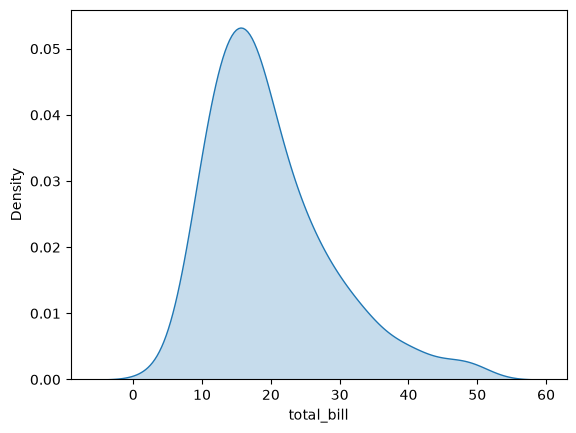

In [31]:
sns.kdeplot(data=df,x='total_bill',fill=True)

# Violine polt= Box + Density plot

<Axes: xlabel='day', ylabel='total_bill'>

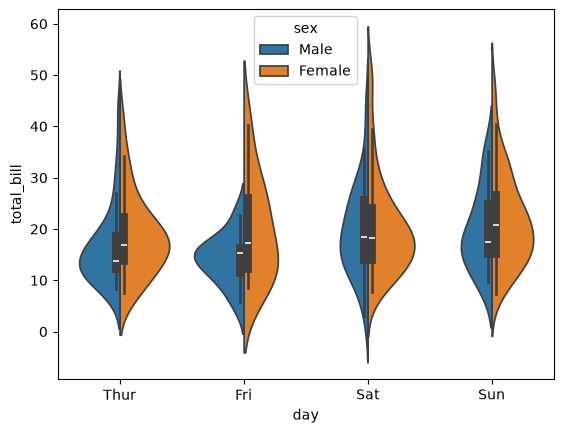

In [33]:
sns.violinplot(data=df,x='day',y='total_bill',hue='sex',split=True)

# Regression Plot

<Axes: xlabel='total_bill', ylabel='tip'>

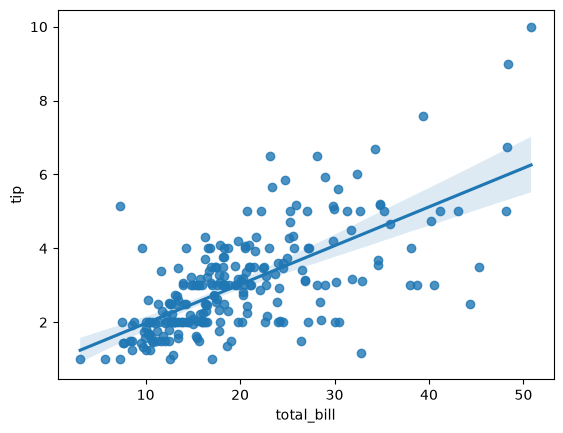

In [34]:
# USE:- To plot the Linear regression model between 2 variables
sns.regplot(data=df,x='total_bill',y='tip')

# FacetGrid

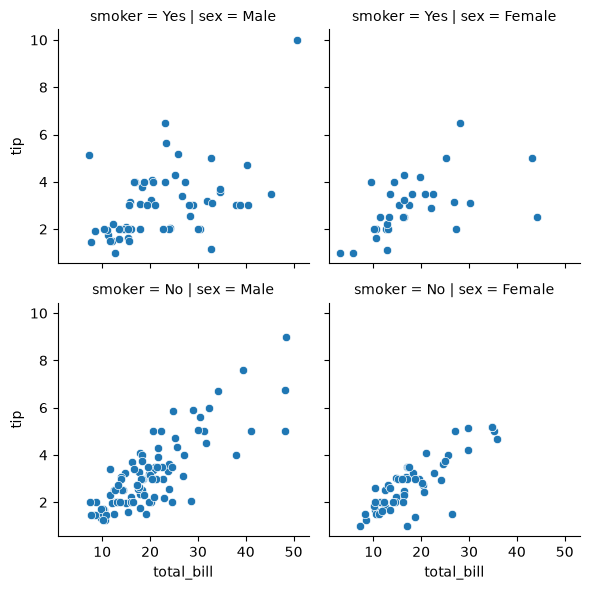

In [38]:
# USE:- Create a multiple plots based on the categorical variable
sns.FacetGrid(data=df,col='sex',row='smoker').map(sns.scatterplot,'total_bill','tip')

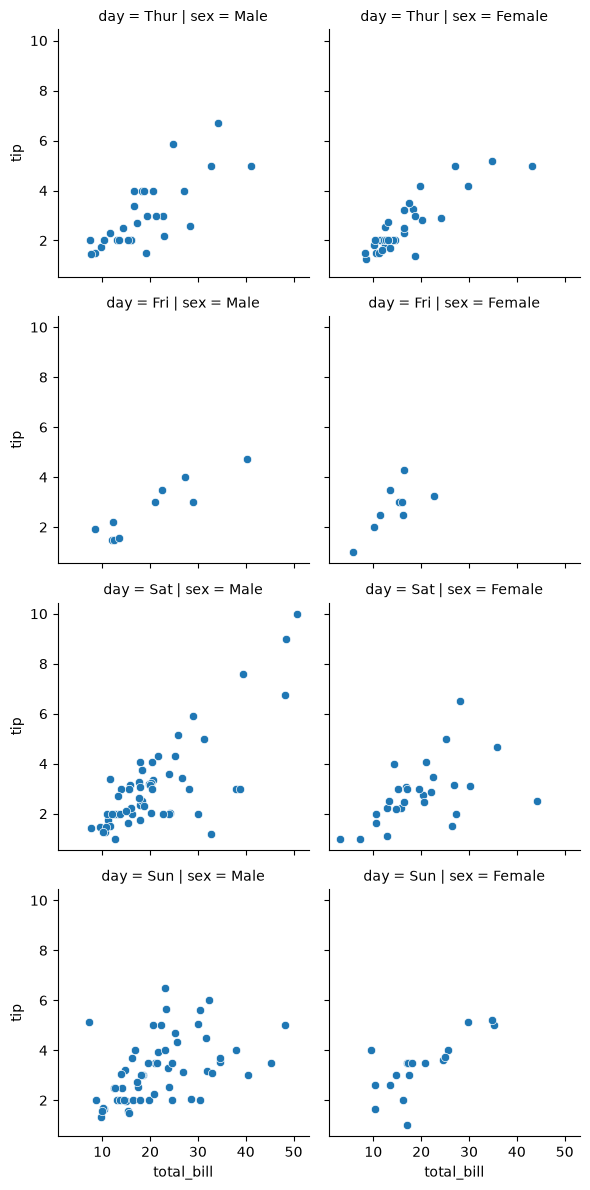

In [39]:
# USE:- Create a multiple plots based on the categorical variable
sns.FacetGrid(data=df,col='sex',row='day').map(sns.scatterplot,'total_bill','tip')

# Joint Plot

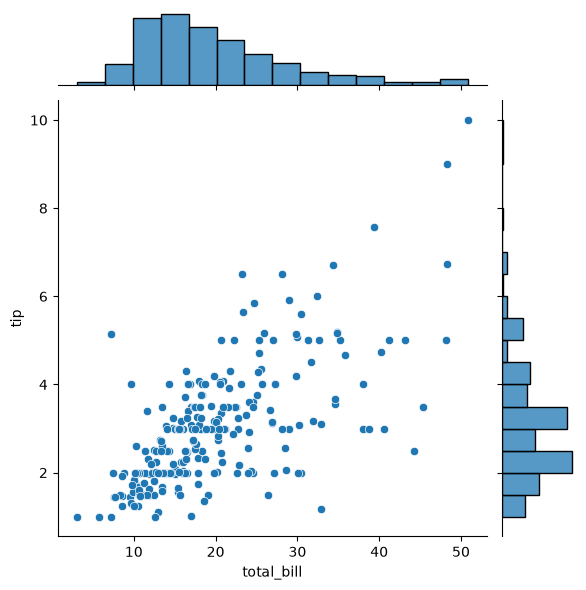

In [40]:
# USE:- This will combined 2 plots:- Histogram + Scatterplot/ KDE plot/ Lineplot/ Regression plot
sns.jointplot(data=df,x='total_bill',y='tip',kind='scatter')